In [10]:
# ============================================================
# EEG MOTOR-TASK SPECTRAL ANALYSIS
# ============================================================
#
# Research question:
# How does EEG spectral activity differ between left- and
# right-hand motor execution, and where on the scalp are
# these differences most pronounced?
#
# Dataset:
# PhysioNet EEG Motor Movement/Imagery Dataset
#
# Analysis:
# 1. Load repeated motor-execution runs
# 2. Inspect experimental events
# 3. Preprocess EEG
# 4. Create event-based epochs
# 5. Screen epochs for large-amplitude artifacts
# 6. Estimate power spectral density (PSD)
# 7. Extract theta, alpha and beta power
# 8. Examine a sensorimotor region of interest
# 9. Compare left-hand and right-hand conditions
# 10. Visualize scalp-level beta differences
# 11. Perform exploratory statistical comparisons
#
# IMPORTANT:
# This is an exploratory single-subject analysis.
# It does NOT establish a general motor-EEG effect across humans.
# ============================================================

In [11]:
# Run this once in a new environment if necessary:
# %pip install mne matplotlib numpy pandas scipy

import os
from pathlib import Path

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import trapezoid
from scipy import stats

from mne.datasets import eegbci


# Reduce MNE's console output so the notebook is easier to read.
mne.set_log_level("WARNING")

# Give dataset downloads a reasonable timeout.
os.environ["POOCH_TIMEOUT"] = "30"

print("MNE version:", mne.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SciPy version:", stats.__version__ if hasattr(stats, "__version__") else "installed")

MNE version: 1.13.2
NumPy version: 2.4.6
Pandas version: 3.0.6
SciPy version: installed


In [12]:
# ============================================================
# ANALYSIS PARAMETERS
# ============================================================

SUBJECT = 1

# Runs 3, 7 and 11 are repeated motor-execution runs
# involving left- vs right-hand movements.
RUNS = [3, 7, 11]

# We will analyze frequencies from 1–40 Hz.
FMIN = 1.0
FMAX = 40.0

# Conventional EEG frequency bands used in this exploratory analysis.
BANDS = {
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
}

# Epochs begin 1 second after the task cue.
# This avoids putting the immediate cue/transition period
# at the center of the spectral analysis.
EPOCH_TMIN = 1.0
EPOCH_TMAX = 3.9

# Peak-to-peak threshold used for simple artifact screening.
# 200 µV = 200e-6 V.
ARTIFACT_THRESHOLD = 200e-6

# Sensorimotor region of interest.
# Not every channel list is guaranteed to be present in
# every recording, so we will check availability below.
SENSORIMOTOR_CHANNELS = [
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "CP3",
    "CP4",
]

# Create folders so figures/results can be saved for GitHub.
FIGURE_DIR = Path("figures")
RESULTS_DIR = Path("results")

FIGURE_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Subject:", SUBJECT)
print("Runs:", RUNS)
print("Frequency range:", f"{FMIN}–{FMAX} Hz")
print("Epoch window:", f"{EPOCH_TMIN}–{EPOCH_TMAX} seconds")
print("Artifact threshold:", f"{ARTIFACT_THRESHOLD * 1e6:.0f} µV")

Subject: 1
Runs: [3, 7, 11]
Frequency range: 1.0–40.0 Hz
Epoch window: 1.0–3.9 seconds
Artifact threshold: 200 µV


In [13]:
# ============================================================
# LOAD THE DATA
# ============================================================

print("Downloading/accessing EEGBCI data...")

eeg_files = eegbci.load_data(
    subjects=SUBJECT,
    runs=RUNS,
    update_path=True,
)

print("\nFiles loaded:")
for file in eeg_files:
    print(file)


# Load each EDF recording.
raw_list = []

for file in eeg_files:
    raw_run = mne.io.read_raw_edf(
        file,
        preload=True,
        verbose=False,
    )
    raw_list.append(raw_run)


# Combine the three repeated runs into one Raw object.
raw = mne.concatenate_raws(raw_list)

# Standardize the EEGBCI channel names so that they correspond
# correctly to standard EEG montage locations.
eegbci.standardize(raw)

# Add standard electrode locations.
montage = mne.channels.make_standard_montage("standard_1005")
raw.set_montage(montage, on_missing="ignore")

print("\n--- DATA LOADED ---")
print("Number of EEG channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Recording duration:", round(raw.times[-1], 2), "seconds")
print("First 10 channel names:")
print(raw.ch_names[:10])

Downloading/accessing EEGBCI data...


c:\Users\Etienne\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Files loaded:
C:\Users\Etienne\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R03.edf
C:\Users\Etienne\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R07.edf
C:\Users\Etienne\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R11.edf

--- DATA LOADED ---
Number of EEG channels: 64
Sampling frequency: 160.0 Hz
Recording duration: 374.99 seconds
First 10 channel names:
['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1']


C:\Users\Etienne\AppData\Local\Temp\ipykernel_29496\4246628174.py:38: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


In [14]:
# ============================================================
# INSPECT EXPERIMENTAL EVENTS
# ============================================================

print("Unique annotation descriptions:")
print(np.unique(raw.annotations.description))


# The dataset uses:
# T0 = rest
# T1 = left-hand movement
# T2 = right-hand movement
#
# We rename these to make the analysis easier to read.
raw.annotations.rename({
    "T0": "rest",
    "T1": "left_hand",
    "T2": "right_hand",
})


# Convert selected annotations into numerical events.
event_mapping = {
    "rest": 1,
    "left_hand": 2,
    "right_hand": 3,
}

events, event_id = mne.events_from_annotations(
    raw,
    event_id=event_mapping,
    verbose=False,
)

print("\nEvent mapping:")
print(event_id)

print("\nNumber of events:")
event_counts = pd.Series(
    [
        {v: k for k, v in event_id.items()}[code]
        for code in events[:, 2]
    ]
).value_counts()

print(event_counts)

Unique annotation descriptions:
['BAD boundary' 'EDGE boundary' 'T0' 'T1' 'T2']

Event mapping:
{'left_hand': 2, 'rest': 1, 'right_hand': 3}

Number of events:
rest          45
left_hand     23
right_hand    22
Name: count, dtype: int64


Showing a short segment of the continuous EEG.
This is a visual sanity check before further analysis.


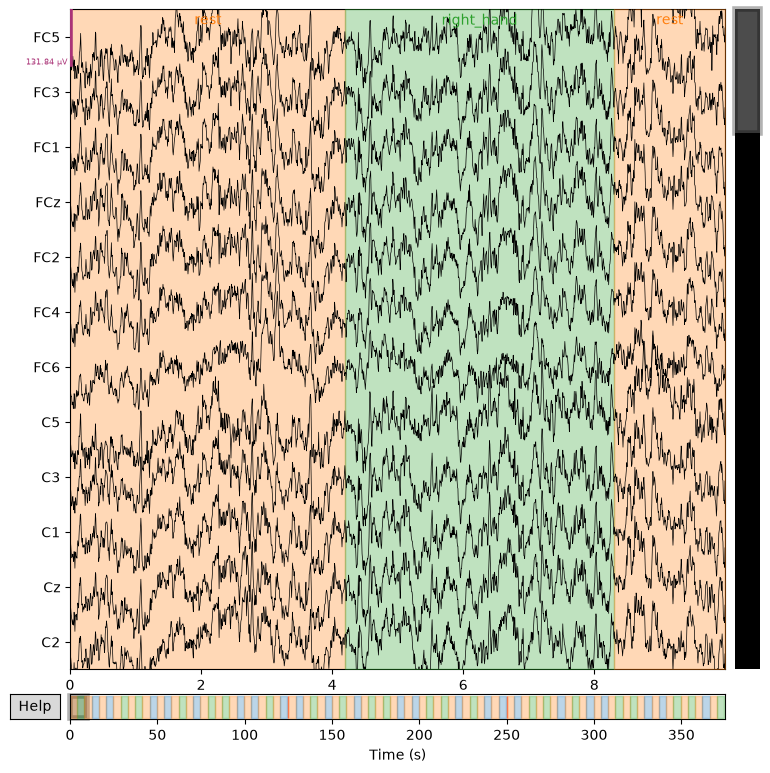

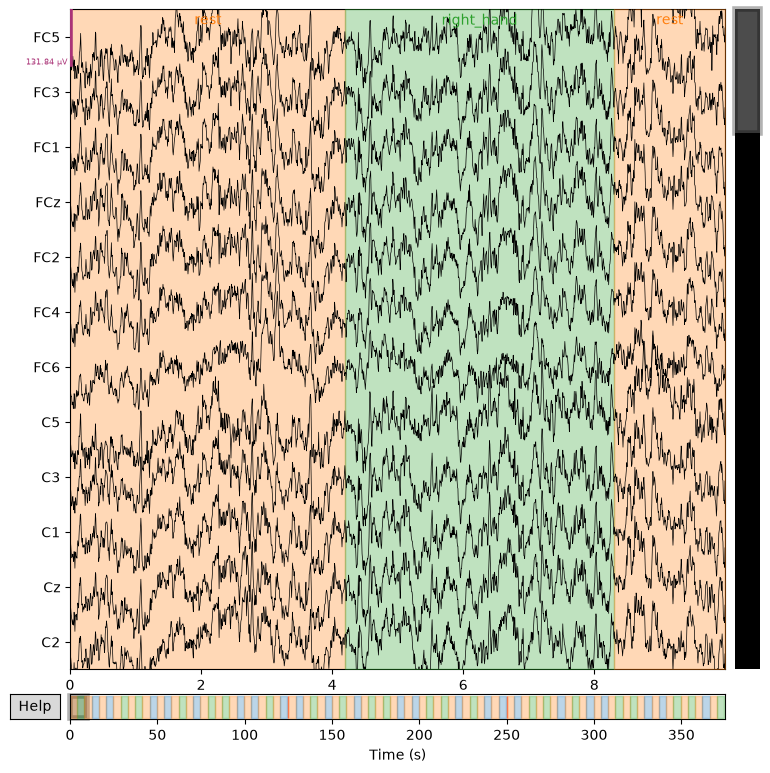

In [15]:
# ============================================================
# INITIAL EEG VISUALIZATION
# ============================================================

print("Showing a short segment of the continuous EEG.")
print("This is a visual sanity check before further analysis.")

raw.plot(
    duration=10,
    n_channels=12,
    scalings="auto",
    title="Raw EEG: Representative 10-second Segment",
)

In [16]:
# ============================================================
# PREPROCESSING
# ============================================================

# Average reference:
# each EEG channel is referenced relative to the average
# electrical potential across the EEG electrodes.
raw.set_eeg_reference(
    projection=True,
    verbose=False,
)


# Create a separate copy so that the original recording
# remains available for comparison if needed.
raw_filtered = raw.copy()


# Band-pass filter:
# retain approximately 1–40 Hz for this analysis.
raw_filtered.filter(
    l_freq=FMIN,
    h_freq=FMAX,
    skip_by_annotation="edge",
    verbose=False,
)

print("--- PREPROCESSING COMPLETE ---")
print(f"Band-pass range: {FMIN}–{FMAX} Hz")
print("Average EEG reference: applied as a projection")
print("60-Hz notch: not used because 60 Hz lies outside the 1–40 Hz analysis range.")

--- PREPROCESSING COMPLETE ---
Band-pass range: 1.0–40.0 Hz
Average EEG reference: applied as a projection
60-Hz notch: not used because 60 Hz lies outside the 1–40 Hz analysis range.


In [17]:
# ============================================================
# EVENT-BASED EPOCHING
# ============================================================

epochs = mne.Epochs(
    raw_filtered,
    events,
    event_id=event_id,
    tmin=EPOCH_TMIN,
    tmax=EPOCH_TMAX,
    baseline=None,
    picks="eeg",
    preload=True,
    reject_by_annotation=True,
    verbose=False,
)

print("--- EPOCHING COMPLETE ---")
print("Epoch window:", f"{EPOCH_TMIN} to {EPOCH_TMAX} seconds")
print("Total epochs before artifact screening:", len(epochs))

for condition in event_id:
    print(
        f"{condition}:",
        len(epochs[condition])
    )

--- EPOCHING COMPLETE ---
Epoch window: 1.0 to 3.9 seconds
Total epochs before artifact screening: 90
left_hand: 23
rest: 45
right_hand: 22


In [18]:
# ============================================================
# SIMPLE ARTIFACT SCREENING
# ============================================================

epoch_data = epochs.get_data()

# Peak-to-peak amplitude for every channel in every epoch.
# Shape before max:
#     epochs × channels
peak_to_peak = np.ptp(epoch_data, axis=2)

# For each epoch, take the largest peak-to-peak amplitude
# observed across all channels.
max_peak_to_peak = peak_to_peak.max(axis=1)

print("--- ARTIFACT SCREENING ---")
print(
    "Peak-to-peak amplitude percentiles (µV):"
)

for percentile in [50, 75, 90, 95, 99]:
    value = np.percentile(max_peak_to_peak, percentile) * 1e6
    print(f"{percentile:>2}th percentile: {value:>8.2f} µV")


# Identify epochs exceeding the predefined threshold.
bad_epoch_indices = np.where(
    max_peak_to_peak > ARTIFACT_THRESHOLD
)[0]

print(
    f"\nEpochs exceeding {ARTIFACT_THRESHOLD * 1e6:.0f} µV:",
    len(bad_epoch_indices),
    f"({100 * len(bad_epoch_indices) / len(epochs):.1f}%)"
)


# Drop those epochs.
epochs.drop(
    bad_epoch_indices,
    reason=f"peak-to-peak > {ARTIFACT_THRESHOLD * 1e6:.0f} µV",
)


print("Remaining clean epochs:", len(epochs))

--- ARTIFACT SCREENING ---
Peak-to-peak amplitude percentiles (µV):
50th percentile:   322.78 µV
75th percentile:   463.73 µV
90th percentile:   542.27 µV
95th percentile:   607.99 µV
99th percentile:   696.76 µV

Epochs exceeding 200 µV: 81 (90.0%)
Remaining clean epochs: 9


In [19]:
# ============================================================
# SENSORIMOTOR REGION OF INTEREST
# ============================================================

available_sensorimotor = [
    ch for ch in SENSORIMOTOR_CHANNELS
    if ch in epochs.ch_names
]

missing_sensorimotor = [
    ch for ch in SENSORIMOTOR_CHANNELS
    if ch not in epochs.ch_names
]

print("Available sensorimotor channels:")
print(available_sensorimotor)

if missing_sensorimotor:
    print("\nNot found:")
    print(missing_sensorimotor)

if len(available_sensorimotor) < 5:
    raise RuntimeError(
        "Too few sensorimotor channels were found for the planned ROI analysis."
    )

sensorimotor_indices = [
    epochs.ch_names.index(ch)
    for ch in available_sensorimotor
]

print("\nUsing", len(sensorimotor_indices), "channels for the sensorimotor ROI.")

Available sensorimotor channels:
['C3', 'C1', 'Cz', 'C2', 'C4', 'CP3', 'CP4']

Using 7 channels for the sensorimotor ROI.


In [20]:
# ============================================================
# POWER SPECTRAL DENSITY
# ============================================================

# Our epochs contain about 465 samples each.
# We therefore use an FFT size that fits comfortably within
# the available epoch length.

spectrum = epochs.compute_psd(
    method="welch",
    fmin=FMIN,
    fmax=FMAX,
    n_fft=256,
    n_per_seg=256,
    verbose=False,
)

psd_data = spectrum.get_data()
freqs = spectrum.freqs

print("--- PSD COMPUTED ---")
print("PSD shape:", psd_data.shape)
print("Frequency range:", round(freqs[0], 2), "to", round(freqs[-1], 2), "Hz")
print("Frequency resolution:", round(freqs[1] - freqs[0], 4), "Hz")

--- PSD COMPUTED ---
PSD shape: (9, 64, 63)
Frequency range: 1.25 to 40.0 Hz
Frequency resolution: 0.625 Hz


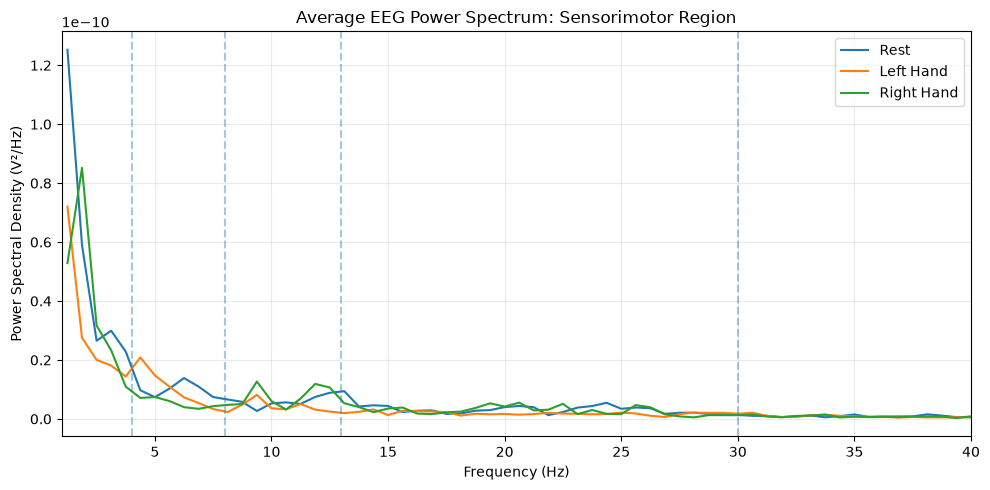

In [21]:
# ============================================================
# SPECTRAL VISUALIZATION
# ============================================================

condition_order = [
    "rest",
    "left_hand",
    "right_hand",
]

fig, ax = plt.subplots(figsize=(10, 5))

for condition in condition_order:

    condition_mask = (
        epochs.events[:, -1] == event_id[condition]
    )

    # Average across epochs and sensorimotor channels.
    mean_psd = psd_data[
        condition_mask
    ][:, sensorimotor_indices, :].mean(axis=(0, 1))

    ax.plot(
        freqs,
        mean_psd,
        label=condition.replace("_", " ").title(),
    )


# Mark the boundaries of our frequency bands.
for boundary in [4, 8, 13, 30]:
    ax.axvline(
        boundary,
        linestyle="--",
        alpha=0.4,
    )

ax.set_title(
    "Average EEG Power Spectrum: Sensorimotor Region"
)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (V²/Hz)")

ax.set_xlim(FMIN, FMAX)
ax.legend()
ax.grid(True, alpha=0.25)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "sensorimotor_psd_by_condition.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [22]:
# ============================================================
# FREQUENCY-BAND POWER
# ============================================================

band_power = {}

for band_name, (low_freq, high_freq) in BANDS.items():

    frequency_mask = (
        (freqs >= low_freq)
        & (freqs <= high_freq)
    )

    # Integrate the PSD over the selected frequency range.
    # Output shape:
    #     epochs × channels
    band_power[band_name] = trapezoid(
        psd_data[:, :, frequency_mask],
        freqs[frequency_mask],
        axis=-1,
    )

    print(
        f"{band_name.capitalize():<6}:",
        f"{low_freq}–{high_freq} Hz"
    )

print("\nBand-power calculation complete.")

Theta : 4.0–8.0 Hz
Alpha : 8.0–13.0 Hz
Beta  : 13.0–30.0 Hz

Band-power calculation complete.


In [23]:
# ============================================================
# RELATIVE BAND POWER
# ============================================================

# Total power across 1–40 Hz.
total_power = trapezoid(
    psd_data,
    freqs,
    axis=-1,
)

relative_power = {}

for band_name in BANDS:

    relative_power[band_name] = (
        band_power[band_name]
        / total_power
    )

print("--- RELATIVE POWER CALCULATED ---")
print(
    "Relative power represents the proportion of 1–40 Hz "
    "power contained within each selected frequency band."
)

--- RELATIVE POWER CALCULATED ---
Relative power represents the proportion of 1–40 Hz power contained within each selected frequency band.


In [24]:
# ============================================================
# RELATIVE BAND POWER
# ============================================================

# Total power across 1–40 Hz.
total_power = trapezoid(
    psd_data,
    freqs,
    axis=-1,
)

relative_power = {}

for band_name in BANDS:

    relative_power[band_name] = (
        band_power[band_name]
        / total_power
    )

print("--- RELATIVE POWER CALCULATED ---")
print(
    "Relative power represents the proportion of 1–40 Hz "
    "power contained within each selected frequency band."
)

--- RELATIVE POWER CALCULATED ---
Relative power represents the proportion of 1–40 Hz power contained within each selected frequency band.


In [25]:
# ============================================================
# BUILD FEATURE TABLE
# ============================================================

# Convert MNE's event codes back into readable condition names.
condition_lookup = {
    int(code): name
    for name, code in event_id.items()
}

conditions = [
    condition_lookup[int(code)]
    for code in epochs.events[:, -1]
]

feature_rows = []

for epoch_index, condition in enumerate(conditions):

    # Select sensorimotor channels for this epoch
    theta_values = band_power["theta"][
        epoch_index,
        sensorimotor_indices,
    ]

    alpha_values = band_power["alpha"][
        epoch_index,
        sensorimotor_indices,
    ]

    beta_values = band_power["beta"][
        epoch_index,
        sensorimotor_indices,
    ]

    theta_relative_values = relative_power["theta"][
        epoch_index,
        sensorimotor_indices,
    ]

    alpha_relative_values = relative_power["alpha"][
        epoch_index,
        sensorimotor_indices,
    ]

    beta_relative_values = relative_power["beta"][
        epoch_index,
        sensorimotor_indices,
    ]

    # Average across the sensorimotor channels
    theta = np.mean(theta_values)
    alpha = np.mean(alpha_values)
    beta = np.mean(beta_values)

    theta_relative = np.mean(theta_relative_values)
    alpha_relative = np.mean(alpha_relative_values)
    beta_relative = np.mean(beta_relative_values)

    # Exploratory spectral ratio
    theta_alpha_ratio = theta / alpha

    feature_rows.append({
        "Epoch": epoch_index,
        "Condition": condition,
        "Theta_Power": theta,
        "Alpha_Power": alpha,
        "Beta_Power": beta,
        "Theta_Relative": theta_relative,
        "Alpha_Relative": alpha_relative,
        "Beta_Relative": beta_relative,
        "Theta_Alpha_Ratio": theta_alpha_ratio,
    })


# Convert our list of dictionaries into a Pandas dataframe.
features_df = pd.DataFrame(feature_rows)

print("--- FEATURE DATASET CREATED ---")
print("Rows:", len(features_df))
print("Columns:", len(features_df.columns))
print()

print(features_df.head())

--- FEATURE DATASET CREATED ---
Rows: 9
Columns: 9

   Epoch  Condition   Theta_Power   Alpha_Power    Beta_Power  Theta_Relative  \
0      0  left_hand  5.543164e-11  2.010708e-11  3.229891e-11        0.276540   
1      1  left_hand  2.143028e-11  8.890310e-12  3.954526e-11        0.133261   
2      2       rest  4.674211e-11  2.211027e-11  5.534138e-11        0.186981   
3      3       rest  2.658526e-11  3.439255e-11  5.063305e-11        0.109662   
4      4  left_hand  3.140841e-11  2.632177e-11  2.702310e-11        0.168719   

   Alpha_Relative  Beta_Relative  Theta_Alpha_Ratio  
0        0.101988       0.162277           2.756822  
1        0.051204       0.234432           2.410521  
2        0.085269       0.218397           2.114045  
3        0.152649       0.224691           0.772995  
4        0.153232       0.155879           1.193248  


In [26]:
# ============================================================
# CONDITION SUMMARY
# ============================================================

condition_summary = (
    features_df["Condition"]
    .value_counts()
    .reindex(condition_order)
)

print("Number of clean epochs per condition:")
print(condition_summary)

Number of clean epochs per condition:
Condition
rest          3
left_hand     4
right_hand    2
Name: count, dtype: int64


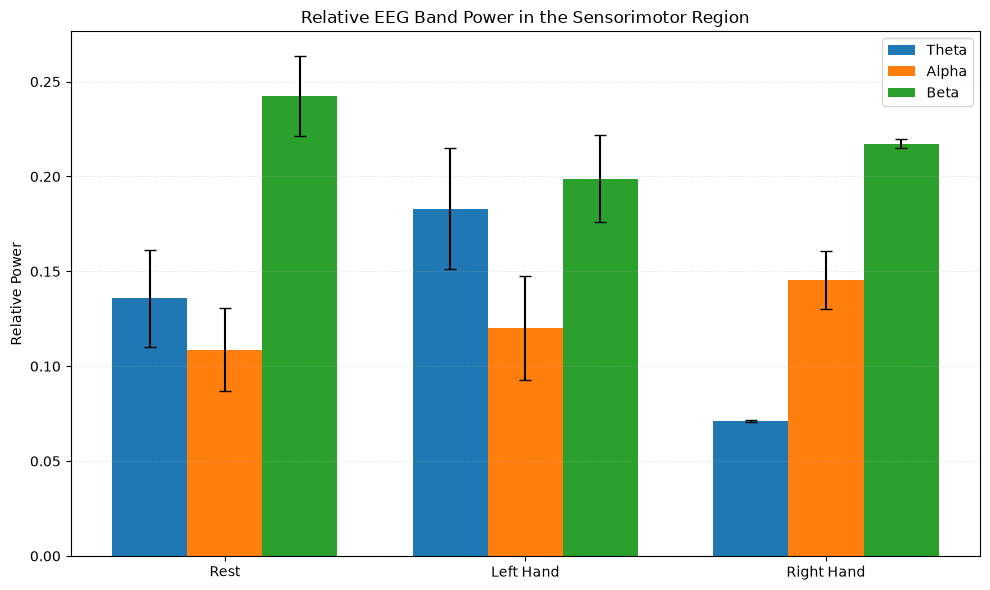

In [27]:
# ============================================================
# BAND-POWER COMPARISON
# ============================================================

plot_bands = [
    "Theta_Relative",
    "Alpha_Relative",
    "Beta_Relative",
]

summary_mean = (
    features_df
    .groupby("Condition")[plot_bands]
    .mean()
    .reindex(condition_order)
)

summary_sem = (
    features_df
    .groupby("Condition")[plot_bands]
    .sem()
    .reindex(condition_order)
)


x = np.arange(len(condition_order))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

for band_index, band in enumerate(plot_bands):

    offset = (
        band_index - 1
    ) * width

    ax.bar(
        x + offset,
        summary_mean[band],
        width,
        yerr=summary_sem[band],
        capsize=4,
        label=band.replace("_Relative", "")
    )


ax.set_xticks(x)
ax.set_xticklabels(
    [
        condition.replace("_", " ").title()
        for condition in condition_order
    ]
)

ax.set_ylabel("Relative Power")
ax.set_title(
    "Relative EEG Band Power in the Sensorimotor Region"
)

ax.legend()
ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.4,
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "relative_band_power_by_condition.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

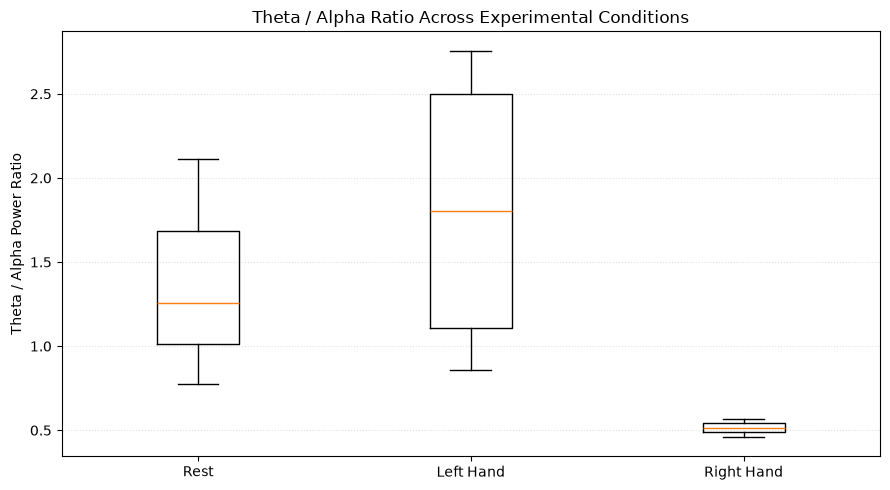

In [28]:
# ============================================================
# THETA / ALPHA RATIO
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

ratio_data = [
    features_df.loc[
        features_df["Condition"] == condition,
        "Theta_Alpha_Ratio",
    ].values
    for condition in condition_order
]

ax.boxplot(
    ratio_data,
    tick_labels=[
        condition.replace("_", " ").title()
        for condition in condition_order
    ],
)

ax.set_ylabel("Theta / Alpha Power Ratio")
ax.set_title(
    "Theta / Alpha Ratio Across Experimental Conditions"
)

ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.4,
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "theta_alpha_ratio_by_condition.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

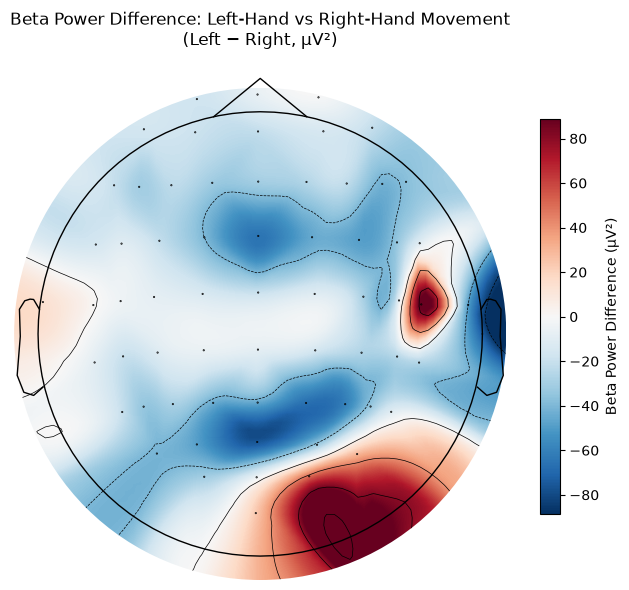

In [29]:
# ============================================================
# TOPOGRAPHIC ANALYSIS
# ============================================================

left_mask = (
    epochs.events[:, -1] == event_id["left_hand"]
)

right_mask = (
    epochs.events[:, -1] == event_id["right_hand"]
)


# Mean beta power at every scalp channel.
left_beta = band_power["beta"][left_mask].mean(axis=0)
right_beta = band_power["beta"][right_mask].mean(axis=0)

# Difference:
# positive = more beta power during left-hand movement
# negative = more beta power during right-hand movement
beta_difference = left_beta - right_beta

# Convert V² to µV² for easier display.
beta_difference_uV2 = beta_difference * 1e12


fig, ax = plt.subplots(figsize=(7, 6))

im, _ = mne.viz.plot_topomap(
    beta_difference_uV2,
    epochs.info,
    ch_type="eeg",
    axes=ax,
    show=False,
)

ax.set_title(
    "Beta Power Difference: Left-Hand vs Right-Hand Movement\n"
    "(Left − Right, µV²)"
)

fig.colorbar(
    im,
    ax=ax,
    shrink=0.75,
    label="Beta Power Difference (µV²)",
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "beta_power_topography_left_vs_right.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [30]:
# ============================================================
# EXPLORATORY STATISTICAL COMPARISON
# ============================================================

left_df = features_df[
    features_df["Condition"] == "left_hand"
]

right_df = features_df[
    features_df["Condition"] == "right_hand"
]


features_to_test = [
    "Theta_Power",
    "Alpha_Power",
    "Beta_Power",
    "Theta_Alpha_Ratio",
]

statistical_results = []

for feature in features_to_test:

    left_values = left_df[feature].values
    right_values = right_df[feature].values

    # Mann–Whitney U is used here as an exploratory
    # non-parametric comparison between the two
    # within-subject trial distributions.
    statistic, p_value = stats.mannwhitneyu(
        left_values,
        right_values,
        alternative="two-sided",
    )

    # Rank-biserial effect size.
    n_left = len(left_values)
    n_right = len(right_values)

    rank_biserial = (
        (2 * statistic)
        / (n_left * n_right)
        - 1
    )

    statistical_results.append({
        "Feature": feature,
        "U_statistic": statistic,
        "Raw_p_value": p_value,
        "Rank_biserial_effect": rank_biserial,
    })


stats_df = pd.DataFrame(statistical_results)

# Four comparisons were made.
# Apply simple Bonferroni correction.
stats_df["Bonferroni_p"] = np.minimum(
    stats_df["Raw_p_value"] * len(features_to_test),
    1.0,
)

print("--- EXPLORATORY STATISTICAL RESULTS ---")

display(stats_df)

--- EXPLORATORY STATISTICAL RESULTS ---


,Feature,U_statistic,Raw_p_value,Rank_biserial_effect,Bonferroni_p
0,Theta_Power,7.0,0.266667,0.75,1.000000
1,Alpha_Power,1.0,0.266667,-0.75,1.000000
2,Beta_Power,1.0,0.266667,-0.75,1.000000
3,Theta_Alpha_Ratio,8.0,0.133333,1.00,0.533333


In [31]:
# ============================================================
# SAVE RESULTS
# ============================================================

features_path = (
    RESULTS_DIR / "eeg_spectral_features.csv"
)

stats_path = (
    RESULTS_DIR / "exploratory_statistics.csv"
)


features_df.to_csv(
    features_path,
    index=False,
)

stats_df.to_csv(
    stats_path,
    index=False,
)


print("Saved:")
print(features_path)
print(stats_path)

print("\nFigures saved to:")
print(FIGURE_DIR.resolve())

Saved:
results\eeg_spectral_features.csv
results\exploratory_statistics.csv

Figures saved to:
C:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures


In [32]:
# ============================================================
# FINAL ANALYSIS SUMMARY
# ============================================================

print("=" * 60)
print("FINAL ANALYSIS SUMMARY")
print("=" * 60)

print("\nDataset")
print(f"  Subject: {SUBJECT}")
print(f"  Runs: {RUNS}")
print(f"  EEG channels: {len(raw.ch_names)}")
print(f"  Sampling rate: {raw.info['sfreq']} Hz")

print("\nEpoching")
print(f"  Window: {EPOCH_TMIN}–{EPOCH_TMAX} s after event onset")
print(f"  Clean epochs: {len(epochs)}")

print("\nConditions")
for condition in condition_order:
    count = len(
        features_df[
            features_df["Condition"] == condition
        ]
    )
    print(f"  {condition}: {count} epochs")

print("\nFrequency bands")
for band, limits in BANDS.items():
    print(f"  {band}: {limits[0]}–{limits[1]} Hz")

print("\nSensorimotor channels")
print(" ", ", ".join(available_sensorimotor))

print("\nMain derived measures")
print("  Theta power")
print("  Alpha power")
print("  Beta power")
print("  Relative band power")
print("  Theta / Alpha ratio")
print("  Left-vs-right beta topography")

print("\nInterpretation note")
print(
    "These results describe spectral differences within the "
    "analyzed EEG recordings. They should not be interpreted "
    "as population-level evidence without analysis of additional subjects."
)

print("=" * 60)

FINAL ANALYSIS SUMMARY

Dataset
  Subject: 1
  Runs: [3, 7, 11]
  EEG channels: 64
  Sampling rate: 160.0 Hz

Epoching
  Window: 1.0–3.9 s after event onset
  Clean epochs: 9

Conditions
  rest: 3 epochs
  left_hand: 4 epochs
  right_hand: 2 epochs

Frequency bands
  theta: 4.0–8.0 Hz
  alpha: 8.0–13.0 Hz
  beta: 13.0–30.0 Hz

Sensorimotor channels
  C3, C1, Cz, C2, C4, CP3, CP4

Main derived measures
  Theta power
  Alpha power
  Beta power
  Relative band power
  Theta / Alpha ratio
  Left-vs-right beta topography

Interpretation note
These results describe spectral differences within the analyzed EEG recordings. They should not be interpreted as population-level evidence without analysis of additional subjects.


In [33]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders in this directory:")
for item in Path.cwd().iterdir():
    print(item)

print("\nFigures folder:")
for item in (Path.cwd() / "figures").iterdir():
    print(item)

print("\nResults folder:")
for item in (Path.cwd() / "results").iterdir():
    print(item)

Current working directory:
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice

Files and folders in this directory:
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\.gitignore
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\eeg_motor_task_analysis_rehearse.ipynb
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\README.md
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\requirements.txt
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\results

Figures folder:
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures\beta_power_topography_left_vs_right.png
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures\relative_band_power_by_condition.png
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures\sensorimotor_psd_by_condition.png
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\figures\theta_alpha_ratio_by_condition.png

Results folder:
c:\Users\Etienne\Desktop\Codes\Comp Neuro Practice\results\eeg_spectr